#Importação das bibliotecaas

In [63]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data
import random

#Criação da função de plot

In [64]:
def mostrar(imagem,titulo,cmap = 'gray',tamanho = 4):
  n= len(imagem)
  plt.figure(figsize = (tamanho * n, tamanho))
  for i in range(n):
    plt.subplot(1,n, i+1)
    plt.imshow(imagem[i],cmap=cmap)
    plt.title(titulo[i])
    plt.axis('off')
plt.show()

#Trabalho parte 1

##Imagem original


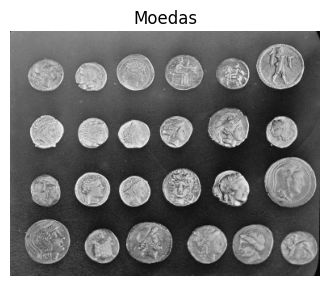

In [65]:
moedas = data.coins()
mostrar([moedas],['Moedas'])

##Imagem 1

In [66]:
suave = cv2.GaussianBlur(moedas,(5,5),0)

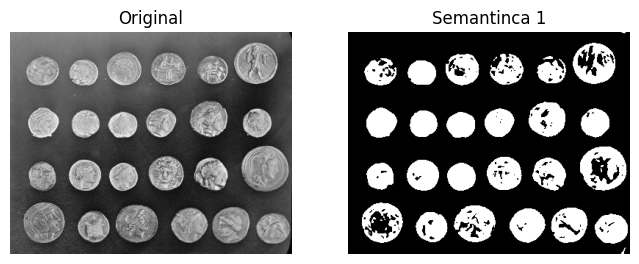

In [71]:
mascara_adapt = cv2.adaptiveThreshold(suave,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,101,-22)
mostrar([moedas,mascara_adapt],['Original','Semantinca 1'])

##Imagem 2

array([[[ 47,  47,  47],
        [123, 123, 123],
        [133, 133, 133],
        ...,
        [ 14,  14,  14],
        [  3,   3,   3],
        [ 12,  12,  12]],

       [[ 93,  93,  93],
        [144, 144, 144],
        [145, 145, 145],
        ...,
        [ 12,  12,  12],
        [  7,   7,   7],
        [  7,   7,   7]],

       [[126, 126, 126],
        [147, 147, 147],
        [143, 143, 143],
        ...,
        [  2,   2,   2],
        [ 13,  13,  13],
        [  3,   3,   3]],

       ...,

       [[ 81,  81,  81],
        [ 79,  79,  79],
        [ 74,  74,  74],
        ...,
        [  6,   6,   6],
        [  4,   4,   4],
        [  7,   7,   7]],

       [[ 88,  88,  88],
        [ 82,  82,  82],
        [ 74,  74,  74],
        ...,
        [  5,   5,   5],
        [  7,   7,   7],
        [  8,   8,   8]],

       [[ 91,  91,  91],
        [ 79,  79,  79],
        [ 68,  68,  68],
        ...,
        [  4,   4,   4],
        [ 10,  10,  10],
        [  7,   7,   7]]], shape=(303, 384, 3), dtype=uint8)
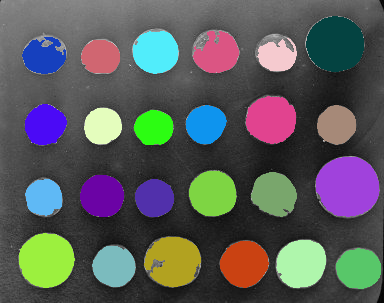

In [49]:
contornos ,_ = cv2.findContours(mascara_adapt,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

contornos = [c for c in contornos if cv2.contourArea(c) > 500]

mascara_final = np.zeros_like(mascara_adapt)


cv2.drawContours(mascara_final,contornos,-1,255, thickness= -1)

moedas_final = cv2.cvtColor(moedas,cv2.COLOR_GRAY2RGB)

for c in contornos:
    cor_aleatoria = (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255))

    cv2.drawContours(moedas_final, [c], -1, cor_aleatoria, thickness=-1)

moedas_final


##Final

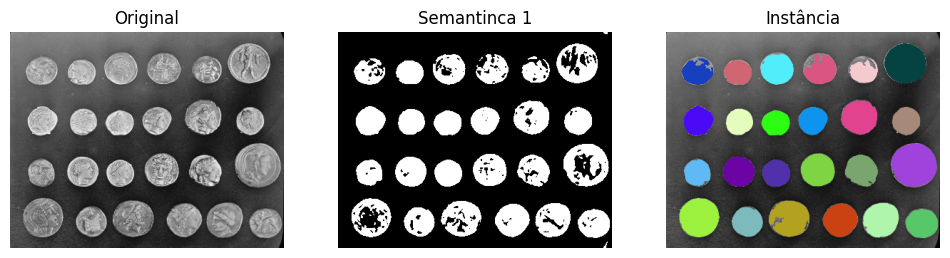

In [50]:
mostrar([moedas, mascara_adapt, moedas_final],['Original','Semantinca 1','Instância'])

#Trabalho parte 2

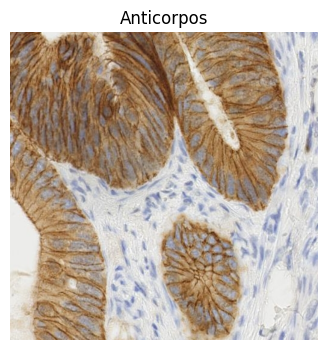

In [159]:
anticorpos = data.immunohistochemistry() #eagle foi a melhor até agora
mostrar([anticorpos],['Anticorpos'])

In [160]:
anticorpos_cinza = cv2.cvtColor(anticorpos,cv2.COLOR_RGB2GRAY)
anticorpos_suave = cv2.GaussianBlur(anticorpos_cinza,(5,5),0)

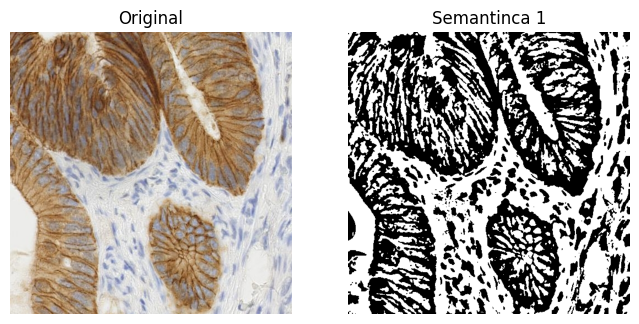

In [161]:
mascara_adapt_anticorpos = cv2.adaptiveThreshold(anticorpos_suave,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,101,-1)
mostrar([anticorpos,mascara_adapt_anticorpos],['Original','Semantinca 1'])

array([[[125, 125, 125],
        [132, 132, 132],
        [124, 124, 124],
        ...,
        [162, 162, 162],
        [177, 177, 177],
        [197, 197, 197]],

       [[112, 112, 112],
        [115, 115, 115],
        [110, 110, 110],
        ...,
        [174, 174, 174],
        [175, 175, 175],
        [183, 183, 183]],

       [[ 98,  98,  98],
        [105, 105, 105],
        [110, 110, 110],
        ...,
        [182, 182, 182],
        [172, 172, 172],
        [172, 172, 172]],

       ...,

       [[218, 218, 218],
        [223, 223, 223],
        [ 25,  74, 216],
        ...,
        [211, 211, 211],
        [211, 211, 211],
        [214, 214, 214]],

       [[214, 214, 214],
        [219, 219, 219],
        [ 25,  74, 216],
        ...,
        [213, 213, 213],
        [208, 208, 208],
        [211, 211, 211]],

       [[219, 219, 219],
        [219, 219, 219],
        [ 25,  74, 216],
        ...,
        [209, 209, 209],
        [206, 206, 206],
        [211, 211, 211]]], shape=(512, 512, 3), dtype=uint8)
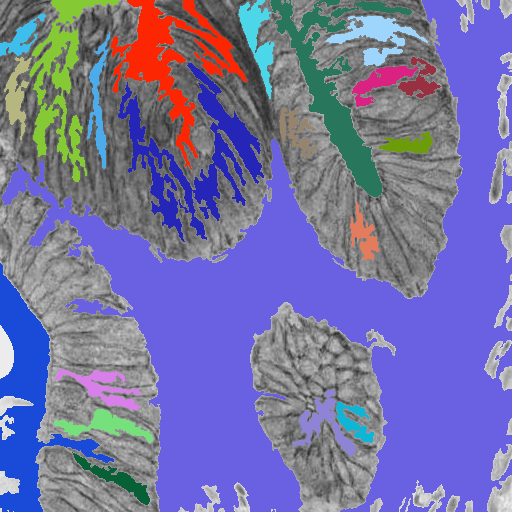

In [166]:
contornos ,_ = cv2.findContours(mascara_adapt_anticorpos,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

contornos = [c for c in contornos if cv2.contourArea(c) > 500]

mascara_final = np.zeros_like(mascara_adapt_anticorpos)


cv2.drawContours(mascara_final,contornos,-1,255, thickness= -1)

anticorpos_final = cv2.cvtColor(anticorpos_cinza,cv2.COLOR_GRAY2RGB)

for c in contornos:
    cor_aleatoria = (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255))

    cv2.drawContours(anticorpos_final, [c], -1, cor_aleatoria, thickness=-1)

anticorpos_final

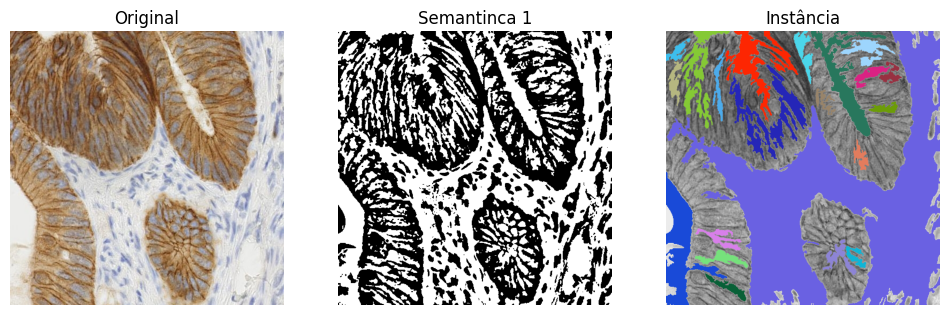

In [168]:
mostrar([anticorpos, mascara_adapt_anticorpos, anticorpos_final],['Original','Semantinca 1','Instância'])

##Explicação

Houve diferença sim, como a imagem da parte 1 é mais simples, com poucos detalhes, e possui somente um tipo de contorno, o de circolos representando a moeda, a implementação foi mais facil de se fazer e teve um sucesso melhor. Enquanto a part2 por ser uma imagem mais complexa a implementação não foi tão acertiva.